## Projeto de Aprendizagem Estatística

**Gabriel R. M. Sanches (15453827)**

**Ian B. Loures (15459667)**

**Marcos O. Salvador (15474845)**

**Projeto MAE0501: Prevendo avaliações de filmes**

Roteiro do notebook:

1. Imports e funções globais
2. Dados e hold-out (20% das linhas separadas antes de qualquer análise)
3. Descrição dos dados
4. Análise exploratória (distribuições, correlação e relação das covariáveis com `stars`)
5. Multicolinearidade e criação de variáveis
6. Modelos, cada um em sua própria seção
7. Comparação final (validação cruzada e hold-out), README e Requirements

Todos os modelos são avaliados pela mesma função `evaluate`, com as mesmas partições de validação cruzada
(5 folds estratificados repetidos 3 vezes em `pure_train`). Cada resultado entra no dicionário `results`;
a comparação conjunta e a avaliação no hold-out aparecem só no final.

### Imports e Funções Globais

In [139]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm, loguniform, randint, uniform
from scipy.optimize import minimize_scalar

import statsmodels.formula.api as smf
from statsmodels.api import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.miscmodels.ordinal_model import OrderedModel

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    cross_val_score, cross_val_predict, RandomizedSearchCV,
)
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from scipy.stats import binned_statistic_2d, gaussian_kde
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch


# Identidade visual usada em todos os gráficos.
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=["#315C8C", "#24A19C", "#F4A261", "#D95D78", "#7B6DCC"],
)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#344054",
    "text.color": "#243447",
    "grid.color": "#DCE3EA",
    "grid.alpha": 0.65,
})
pd.set_option("display.max_colwidth", None)

SEED = 2026
DATA = Path("")
DATA.mkdir(exist_ok=True)

#### Métrica e avaliação dos modelos

In [140]:
def rmse_clipped(y_true, y_pred):
    """
    RMSE after clipping predictions to [0, 5].

    Matches the competition metric, where predictions are limited to the
    valid star range before scoring.

    Parameters
    ----------
    y_true : array-like
        Observed star ratings.
    y_pred : array-like
        Raw model predictions (may fall outside [0, 5]).

    Returns
    -------
    float
        Root mean squared error between y_true and the clipped predictions.
    """
    return np.sqrt(mean_squared_error(y_true, np.clip(y_pred, 0, 5)))

scorer = make_scorer(rmse_clipped, greater_is_better=False)


evaluation_specs = []
results = {}

def evaluate(model, X, y):
    """
    Returns (mean CV RMSE, SE, variables used).
    Also stores the estimator and feature names for the final hold-out evaluation.
    """
    s = -cross_val_score(model, X, y, cv=cv, scoring=scorer)
    cols = list(X.columns)
    if hasattr(model, "named_steps") and "sequentialfeatureselector" in model.named_steps:
        fitted = clone(model).fit(X, y)
        cols = list(X.columns[fitted.named_steps["sequentialfeatureselector"].get_support()])

    evaluation_specs.append((clone(model), X.copy()))
    return round(s.mean(), 4), round(s.std() / np.sqrt(len(s)), 4), ", ".join(cols)


def results_table(names=None):
    """
    Table of CV results stored in `results` (optionally only the rows in `names`).
    """
    table = pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T
    return table if names is None else table.loc[names]


def selected_linear():
    """
    Build a linear regression pipeline with forward variable selection.

    Steps: standardize -> forward selection -> OLS on the chosen variables.
    Selection uses an inner 5-fold CV on the training fold, and stops adding
    variables when the CV RMSE improves by less than `tol` (0.002). Lower
    `tol` keeps more variables.

    Returns a fresh, unfitted pipeline each call so evaluate() can clone it
    per fold. Because selection sits inside the pipeline, it is redone on
    every training fold and the CV RMSE is not optimistic.

    Caveat: forward selection is greedy and can stop early when variables
    only help in combination.

    Returns
    -------
    sklearn.pipeline.Pipeline
    """
    return make_pipeline(
        StandardScaler(),
        SequentialFeatureSelector(
            LinearRegression(),
            n_features_to_select="auto", tol=0.002,
            direction="forward",
            scoring="neg_root_mean_squared_error", cv=5),
        LinearRegression())


def oof_residuals(model, Xm, y):
    """
    Out-of-fold predictions and residuals for diagnostic plots.

    Each row is predicted by a model that did not see it, using a single
    stratified 5-fold split (cross_val_predict needs every row predicted
    exactly once, so it cannot use the repeated `cv` list). Uses the globals
    `SEED` and `strata` (genre + stars label) for reproducible, stratified folds.

    Parameters
    ----------
    model : sklearn estimator or Pipeline
        Unfitted model to diagnose.
    Xm : pd.DataFrame
        Feature matrix to fit on (pass the one you want to diagnose).
    y : pd.Series
        Target (stars).

    Returns
    -------
    pred : np.ndarray
        Out-of-fold predictions, clipped to [0, 5].
    resid : pd.Series
        y - pred. Positive values mean the model underpredicted.
    """
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred = np.clip(cross_val_predict(model, Xm, y, cv=skf.split(Xm, strata)), 0, 5)
    return pred, y - pred

#### Engenharia de variáveis e matrizes de modelagem

Todas as variáveis derivadas são criadas por `add_features`, e cada matriz de modelagem (`X`, `X2`, ..., `X9`)
tem uma função `build_*` própria. Assim a mesma transformação é aplicada em `pure_train` e em `hold_out`,
e a avaliação final reconstrói automaticamente a matriz de cada modelo.

In [141]:
def share_match(data):
    """
    Share of the user's history in the movie's genre
    (share_action if genre == "action", share_comedy if "comedy", share_drama if "drama").
    """
    return data.apply(lambda r: r[f"share_{r['genre']}"], axis=1)


def add_features(data):
    """
    Return a copy of `data` with every derived variable used in the project.

    - log_user_n_ratings, log_movie_n_ratings: log(1 + counts), reduce the right skew.
    - share_match: affinity of the user with the movie's genre. Replaces the three
      share_* variables, which sum to 1 and are highly collinear.
    - age_x_year: interaction age x release_year.
    - age_at_release: user's age when the movie was released.
    - genre_comedy, genre_drama: dummies for genre (action is the reference).
    """
    out = data.copy()
    
    out["log_user_n_ratings"] = np.log1p(out["user_n_ratings"])

    out["log_movie_n_ratings"] = np.log1p(out["movie_n_ratings"])
    
    out["share_match"] = share_match(out)
    
    out["age_x_year"] = out["age"] * out["release_year"]
    
    out["age_at_release"] = out["age"] - (2026 - out["release_year"])
    
    for g in ["comedy", "drama"]:
        out[f"genre_{g}"] = (out["genre"] == g).astype(float)
    return out


# Variáveis originais (one-hot de genre, sem share_drama para evitar colinearidade perfeita).
COLS_X = ["user_avg_stars", "user_n_ratings", "age", "share_action", "share_comedy",
          "movie_avg_stars", "movie_n_ratings", "release_year",
          "genre_comedy", "genre_drama"]

# Regressão linear saturada - Todas as variáveis.
COLS_X7 = ["user_avg_stars", "log_user_n_ratings", "age", "share_match",
           "age_x_year", "age_at_release", "movie_avg_stars", "log_movie_n_ratings",
          "genre_comedy", "genre_drama"]

# Regressão linear com tratamento de multicolinearidade (share_match no lugar dos share_*).
COLS_X8 = ["user_avg_stars", "log_user_n_ratings", "log_movie_n_ratings", "movie_avg_stars",
           "release_year", "share_match", "genre_comedy", "genre_drama"]

# Regressão logística ordinal.
COLS_X9 = ["user_avg_stars", "log_user_n_ratings", "age", "movie_avg_stars",
           "release_year", "share_match", "genre_comedy", "genre_drama"]


def build_X(data):
    """Original variables + genre dummies."""
    return add_features(data)[COLS_X].copy()

def build_X2(data):
    """X + share_match."""
    Xk = build_X(data)
    Xk["share_match"] = share_match(data)
    return Xk

def build_X3(data):
    """X + ln(share_match)."""
    Xk = build_X2(data)
    Xk["share_match"] = np.log(Xk["share_match"])
    return Xk

def build_X5(data):
    """X3 + interactions genre x ln(share_match)."""
    Xk = build_X3(data)
    for g in ["genre_comedy", "genre_drama"]:
        Xk[f"sm_x_{g}"] = Xk["share_match"] * Xk[g]
    return Xk

def build_X6(data):
    """X3 + age_x_year + age_at_release."""
    Xk = build_X3(data)
    Xk["age_x_year"] = Xk["age"] * Xk["release_year"]
    Xk["age_at_release"] = Xk["age"] - (2026 - Xk["release_year"])
    return Xk

def build_X7(data):
    """Saturated linear model."""
    return add_features(data)[COLS_X7].copy()

def build_X8(data):
    """Linear model with share_match (multicollinearity treated)."""
    return add_features(data)[COLS_X8].copy()

def build_X9(data):
    """Ordinal logistic regression."""
    return add_features(data)[COLS_X9].copy()


FEATURE_SETS = {
    "X": build_X, "X2": build_X2, "X3": build_X3, "X4": build_X4, "X5": build_X5,
    "X6": build_X6, "X7": build_X7, "X8": build_X8, "X9": build_X9,
}


def vif_table(Xv, constant=True):
    """
    Variance inflation factor of each column of `Xv`.
    With constant=True an intercept is added (and not reported).
    """
    Xv = Xv.astype(float)
    start = 0
    if constant:
        Xv = add_constant(Xv)
        start = 1
    return pd.DataFrame({
        "Variável": Xv.columns[start:],
        "VIF": [variance_inflation_factor(Xv.to_numpy(), i)
                for i in range(start, Xv.shape[1])],
    }).sort_values("VIF", ascending=False)

#### Estimadores próprios

A regressão ordinal (statsmodels) e o K-Means + K-NN não existem prontos no sklearn. As classes abaixo
dão a eles a mesma interface (`fit` / `predict`) dos demais modelos, para que passem pela mesma `evaluate`
e pela mesma avaliação no hold-out.

In [142]:
class OrdinalRegressor(RegressorMixin, BaseEstimator):
    """
    Ordinal logistic regression (statsmodels OrderedModel) with an sklearn interface.

    predict returns the expected number of stars: sum_k k * P(stars = k).
    """
    def __init__(self, distr="logit"):
        self.distr = distr

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.classes_ = np.sort(np.unique(y))
        y_cat = pd.Categorical(y, categories=self.classes_, ordered=True)
        self.result_ = OrderedModel(
            y_cat, np.asarray(X, dtype=float), distr=self.distr
        ).fit(method="bfgs", disp=False)
        return self

    def predict(self, X):
        proba = np.asarray(self.result_.predict(np.asarray(X, dtype=float)))
        return proba @ self.classes_


class KMeansCentroidRegressor(RegressorMixin, BaseEstimator):
    """
    K-Means + K-NN on the centroids.

    fit: K-Means finds `n_clusters` groups in the training rows.
    predict: a 1-NN on the centroids assigns each new row to the closest group,
    and the prediction is the mean of stars of the training rows in that group.
    """
    def __init__(self, n_clusters=6, random_state=None):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.kmeans_ = KMeans(n_clusters=self.n_clusters,
                              random_state=self.random_state, n_init=10).fit(X)
        self.knn_ = KNeighborsClassifier(n_neighbors=1).fit(
            self.kmeans_.cluster_centers_, np.arange(self.n_clusters))
        self.group_means_ = pd.Series(y).groupby(self.kmeans_.labels_).mean()
        self.global_mean_ = y.mean()
        return self

    def predict(self, X):
        groups = self.knn_.predict(np.asarray(X, dtype=float))
        return self.group_means_.reindex(groups).fillna(self.global_mean_).to_numpy()

#### Funções de gráficos

In [143]:
def plot_panel(data, cols, plot_func, ncols=3,
               title="Distribuição das variáveis numéricas", **kwargs):
    """Panel with one `plot_func` (e.g. sns.histplot) per column of `data`."""
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.5 * ncols, 3.8 * nrows),
        squeeze=False
    )

    axes = axes.ravel()
    palette = sns.color_palette("husl", len(cols))

    for i, (ax, col) in enumerate(zip(axes, cols)):

        plot_func(
            data=data,
            x=col,
            ax=ax,
            color=palette[i],
            edgecolor="white",
            linewidth=0.6,
            **kwargs
        )

        nome = col.replace("_", " ").title()

        ax.set_title(nome, loc="left", fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel(nome, fontsize=10)
        ax.set_ylabel("Densidade" if kwargs.get("stat") == "density" else "Frequência")

        ax.grid(axis="y", alpha=0.2, linestyle="--")
        ax.grid(axis="x", visible=False)

        ax.tick_params(axis="both", labelsize=9)
        sns.despine(ax=ax)

    for ax in axes[len(cols):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.02)
    fig.tight_layout()
    plt.show()


def fix_axes(ax):
    """Fix axes to make the plot consistent."""
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=-0.15, top=5.15)

### Dados e Hold-Out

In [144]:
df = pd.read_csv("train.csv")

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
print(strata.value_counts().min(), "linhas no menor estrato")

62 linhas no menor estrato


O menor estrato (gênero, estrelas) tem 62 linhas, então podemos tranquilamente dividir o conjunto de dados
entre treino e teste (hold-out). Por motivos empíricos, iremos segurar 20% das linhas para teste.

A partir daqui, **toda** a análise exploratória, a seleção de variáveis e a validação cruzada usam apenas
`pure_train`. O `hold_out` só é usado na comparação final, o que mantém essa estimativa independente da
escolha dos modelos.

In [145]:
pure_train, hold_out = train_test_split(
    df, test_size=0.2, stratify=strata, random_state=SEED
)
pure_train = pure_train.reset_index(drop=True)
hold_out = hold_out.reset_index(drop=True)

pure_train.to_csv(DATA / "pure_train.csv", index=False)
hold_out.to_csv(DATA / "hold_out.csv", index=False)
print("Treino puro:", pure_train.shape, "Hold-out:", hold_out.shape)

Treino puro: (3200, 12) Hold-out: (800, 12)


In [146]:
df = pure_train.copy()

X = build_X(df)
y = df["stars"]

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X, strata))

### Descrição dos Dados

O arquivo `train.csv` contém 4.000 observações (3.200 em `pure_train` e 800 em `hold_out`). Os exemplos abaixo
correspondem à primeira linha do arquivo. Cada linha representa uma combinação entre usuário e filme; a variável
resposta é a nota atribuída, de 0 a 5 estrelas. Os dados são fictícios e simulam avaliações de uma plataforma de filmes.

#### Identificação e resposta

| Variável | O que representa | Exemplo |
|---|---|---|
| `pair_id` | Identificador único da combinação usuário–filme. Serve para identificar a linha, não como preditor. | `P00001` |
| `stars` | Nota dada pelo usuário ao filme; variável que queremos explicar ou prever. | `3` estrelas |

#### Características do usuário

| Variável | O que representa | Exemplo |
|---|---|---|
| `user_avg_stars` | Média das notas que o usuário deu a outros filmes. | `2,99` estrelas |
| `user_n_ratings` | Quantidade de avaliações anteriores do usuário. | `15` avaliações |
| `age` | Idade do usuário, em anos. | `48` anos |
| `share_action` | Proporção de filmes de ação no histórico do usuário. | `0,315` = 31,5% |
| `share_comedy` | Proporção de comédias no histórico do usuário. | `0,501` = 50,1% |
| `share_drama` | Proporção de dramas no histórico do usuário. | `0,184` = 18,4% |

As três proporções de gênero somam 1. Por isso, ao usar intercepto em uma regressão, incluímos apenas duas delas
para evitar colinearidade perfeita.

#### Características do filme

| Variável | O que representa | Exemplo |
|---|---|---|
| `movie_avg_stars` | Média das notas recebidas anteriormente pelo filme. | `3,61` estrelas |
| `movie_n_ratings` | Quantidade de avaliações anteriores do filme. | `71` avaliações |
| `genre` | Gênero do filme: ação, comédia ou drama. | `drama` |
| `release_year` | Ano de lançamento do filme. | `2012` |

As médias e contagens anteriores são preditores importantes. Para evitar vazamento de informação, elas devem ter
sido calculadas sem incluir a nota que o modelo está tentando prever.

### Análise Exploratória

Toda a análise exploratória usa somente `pure_train` (`df`).

#### Estatísticas Descritivas

In [147]:
num = df.select_dtypes(include="number").columns.drop("stars")
cat = df.select_dtypes(include=["object", "category", "string"]).columns
cat = cat[~cat.isin(["pair_id", "stars"])]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
user_avg_stars,3200.0,3.332472,0.705261,1.180,2.83000,3.340,3.80000,5.000
user_n_ratings,3200.0,57.632188,83.987678,3.000,14.00000,27.000,60.00000,1016.000
age,3200.0,36.442188,13.994342,16.000,24.00000,35.500,47.00000,79.000
share_action,3200.0,0.390455,0.190480,0.043,0.23775,0.369,0.53300,0.862
share_comedy,3200.0,0.295683,0.116084,0.071,0.20800,0.282,0.37025,0.722
share_drama,3200.0,0.313863,0.208906,0.031,0.13400,0.236,0.51000,0.819
movie_avg_stars,3200.0,3.011856,0.756041,0.310,2.51000,3.000,3.53000,5.000
movie_n_ratings,3200.0,54.559375,69.819776,5.000,16.00000,34.000,66.25000,1345.000
release_year,3200.0,2004.183750,14.962326,1970.000,1993.00000,2008.000,2017.00000,2024.000


#### Histogramas das Variáveis Numéricas

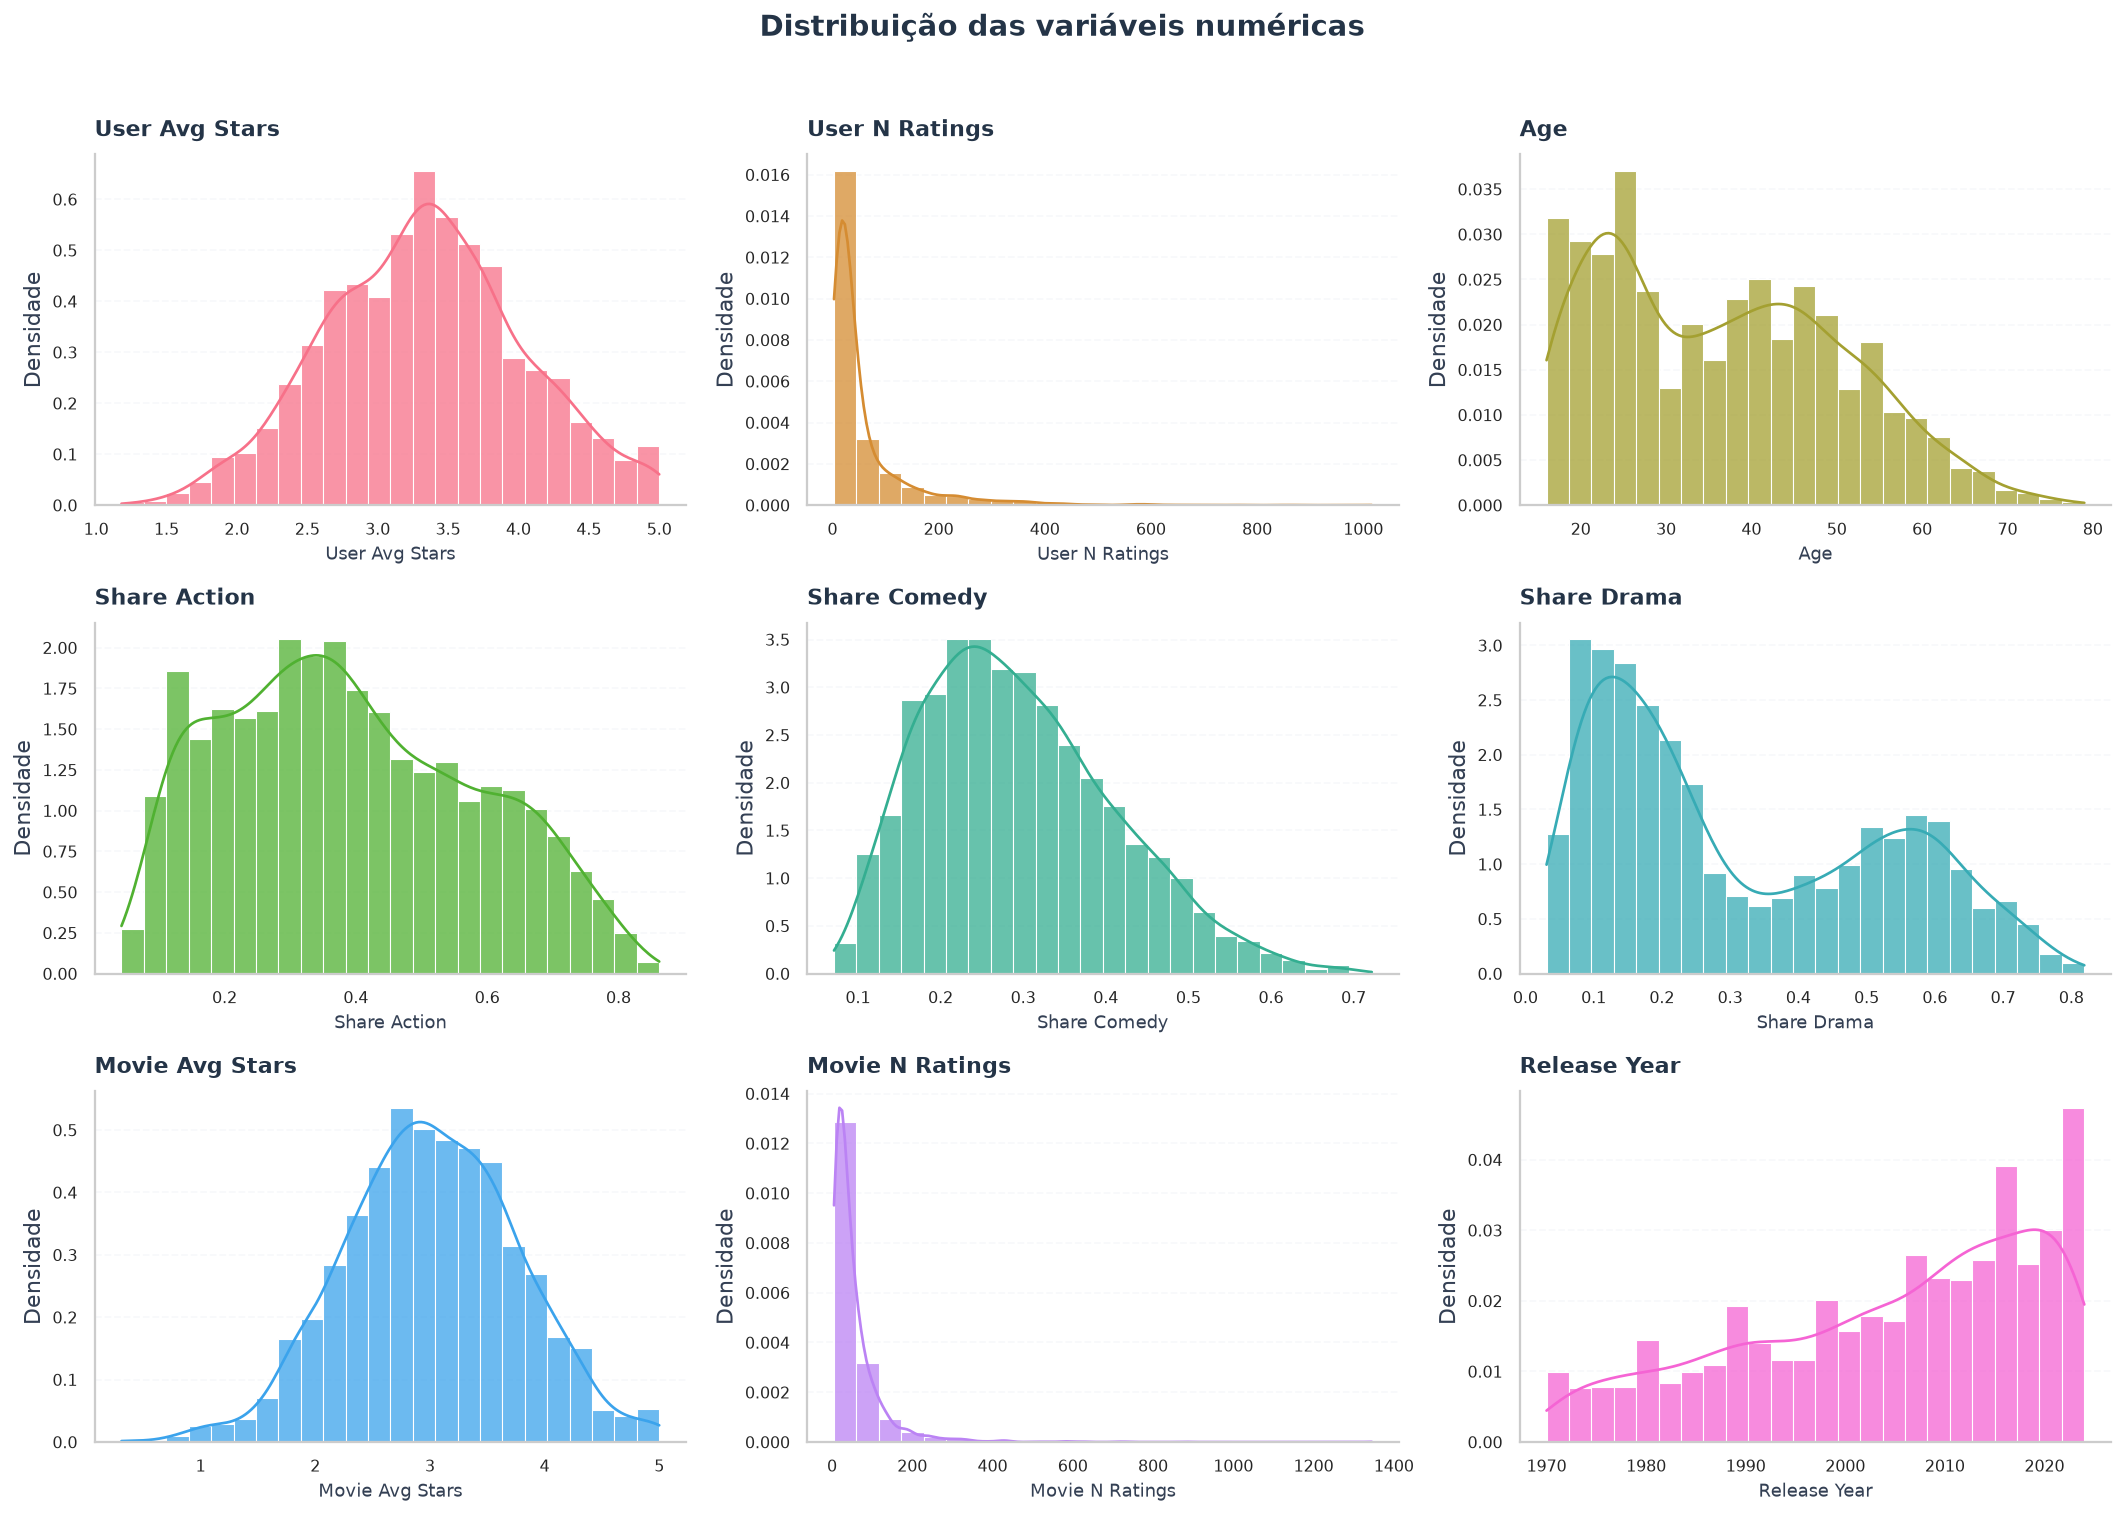

In [148]:
plot_panel(
    df,
    num,
    sns.histplot,
    kde=True,
    stat="density",
    bins=24,
    alpha=0.75
)

Para as variáveis de contagem como `movie_n_ratings` e `user_n_ratings` vemos uma grande inflação em valores menores, corroborando para a possibilidade de transformação em tais variáveis para conseguir maior variabilidade e capacidade de análise em nossos modelos.

#### Distribuição das Variáveis Categóricas e Ordinais

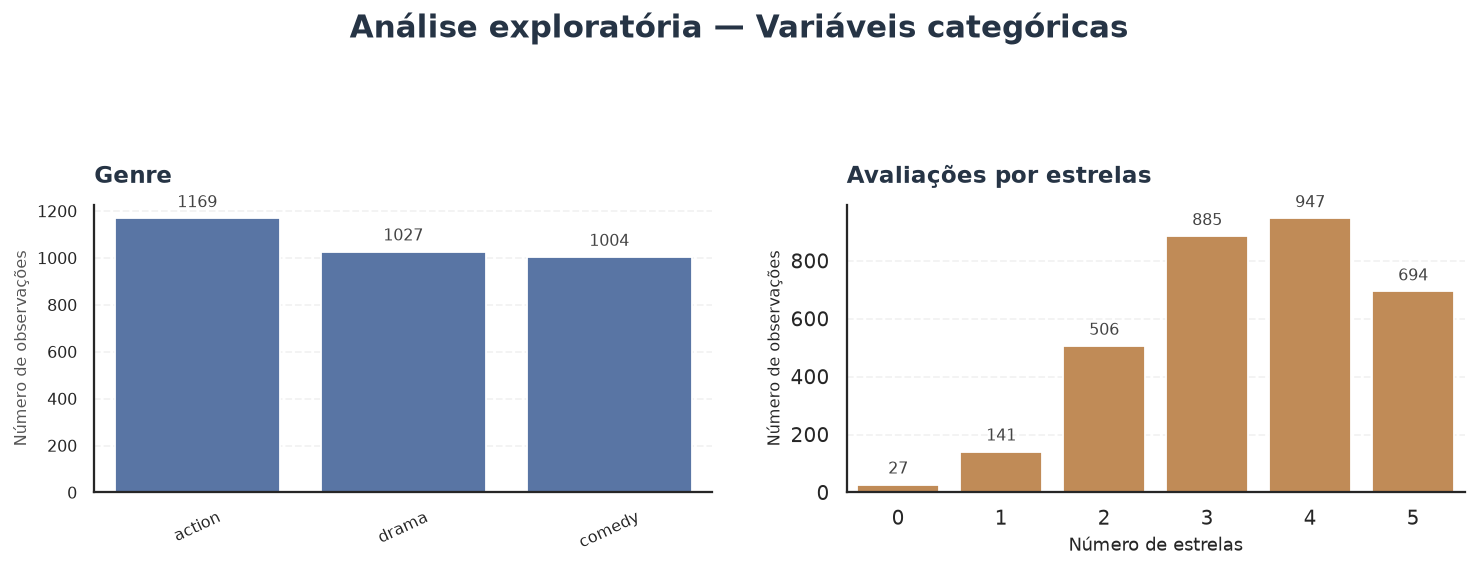

In [149]:
n = len(cat) + 1
ncols = min(n, 3)
nrows = math.ceil(n / ncols)
colors = sns.color_palette("deep", n_colors=n)

with sns.axes_style("white"):
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(6 * ncols, 4.5 * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    # Variáveis categóricas
    for i, col in enumerate(cat):
        ax = axes[i]
        order = df[col].value_counts().index

        sns.countplot(
            data=df, x=col, order=order, color=colors[i],
            edgecolor="white", linewidth=1, ax=ax
        )
        for container in ax.containers:
            ax.bar_label(container, padding=4, fontsize=9, color="#444444")

        ax.set_title(col.replace("_", " ").title(), loc="left", fontsize=13,
                     fontweight="bold", color="#263445", pad=12)
        ax.set_xlabel("")
        ax.set_ylabel("Número de observações", fontsize=9, color="#555555")
        ax.tick_params(axis="x", rotation=25, labelsize=9)
        ax.tick_params(axis="y", labelsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.25)
        ax.set_axisbelow(True)
        sns.despine(ax=ax, left=False, bottom=False)

    # Avaliações
    ax = axes[len(cat)]
    sns.countplot(
        data=df, x="stars", order=sorted(df["stars"].dropna().unique()),
        color="#D28B45", edgecolor="white", linewidth=1, ax=ax
    )
    for container in ax.containers:
        ax.bar_label(container, padding=4, fontsize=9, color="#444444")

    ax.set_title("Avaliações por estrelas", loc="left", fontsize=13,
                 fontweight="bold", color="#263445", pad=12)
    ax.set_xlabel("Número de estrelas", fontsize=10)
    ax.set_ylabel("Número de observações", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

    # Ocultar espaços vazios
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle("Análise exploratória — Variáveis categóricas", fontsize=17,
                 fontweight="bold", color="#263445", y=1.02)
    fig.tight_layout(pad=2.5)
    plt.show()

#### Análise de Correlação das Covariáveis

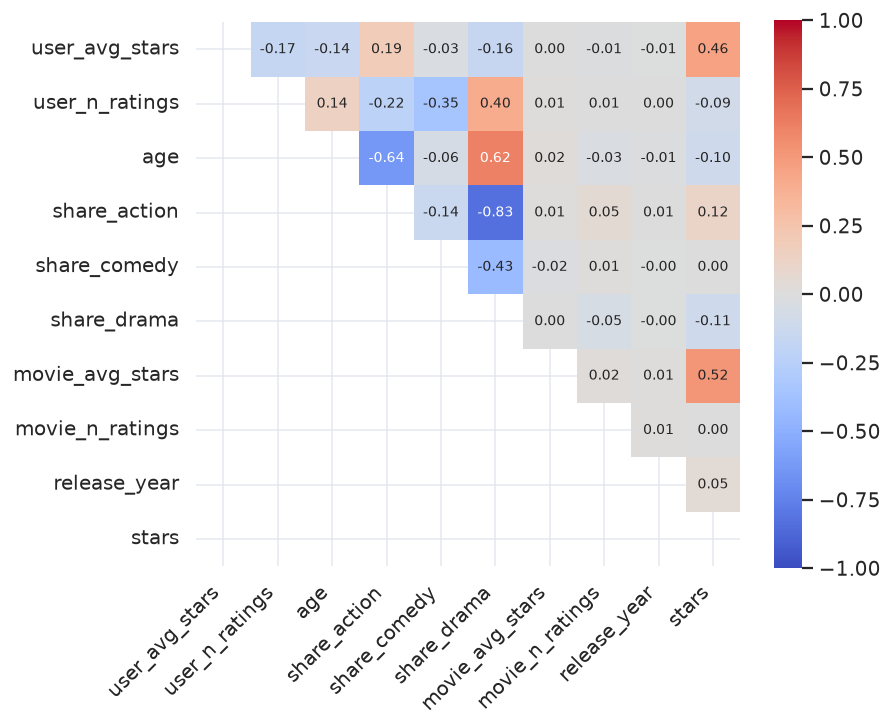

In [150]:
df_num = df[num]
corr = df.select_dtypes(include="number").corr()
mascara = np.tril(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

É possível observar que as variáveis `share_drama`, `share_comedy` e `share_action` produzem enorme multicolineariedade, assim é necessário tratar esse comportamento

#### Tratamento de multicolineariedade

Através da métrica de VIF (Variance Inflation Factor) podemos observar para as variáveis selecionadas, quais produzem maior colineariedade entre elas.

In [151]:
# VIF sem intercepto com todas as variáveis numéricas originais.
vif_df = vif_table(df_num, constant=False)
vif_df

,Variável,VIF
5,share_drama,171421.997546
3,share_action,142502.594935
4,share_comedy,52926.506465
2,age,1.774515
1,user_n_ratings,1.287841
0,user_avg_stars,1.062459
7,movie_n_ratings,1.004953
6,movie_avg_stars,1.002621
8,release_year,1.001688


É notável o que acabamos de evidenciar, sem perda de generalidade, retirando `share_comedy`:

In [152]:
# Com intercepto, retirando share_comedy (as três proporções somam 1).
vif_df2 = vif_table(df_num.drop(columns=["share_comedy"]))
vif_df2

,Variável,VIF
4,share_drama,4.125402
3,share_action,3.791616
2,age,1.774211
1,user_n_ratings,1.287838
0,user_avg_stars,1.062459
6,movie_n_ratings,1.004185
5,movie_avg_stars,1.001796
7,release_year,1.000376


O VIF diminua significativamente, sobretudo ainda temos uma perda de informação e uma pequena multicolineariedade em nossos dados. Assim incluímos uma nova variável `share_match` a qual consiste em uma variável que compõe a proporção do histórico do usuário para um gênero em consonância ao gênero do filme. Assim não precisamos carregar informação desncessária como as demais proporções. 

#### Relação das Covariáveis com `stars`

In [153]:
rng = np.random.default_rng(0)

# Jittered stars: adicionamos pequenos distúrbios no valor de estrelas para a nuvem de pontos ficar mais visível
y_jit = (df["stars"] + rng.uniform(-0.15, 0.15, len(df))).clip(0, 5)

# share_match: incluímos uma variável nova (proporção do histórico do usuário no gênero do filme)
df["share_match"] = share_match(df)
df["log_user_n_ratings"] = np.log1p(df["user_n_ratings"])
df["log_movie_n_ratings"] = np.log1p(df["movie_n_ratings"])


feats = ["user_avg_stars", "age",
         "share_action", "share_comedy", "share_drama",
         "movie_avg_stars", "release_year",
         "share_match", "log_user_n_ratings", "log_movie_n_ratings"]

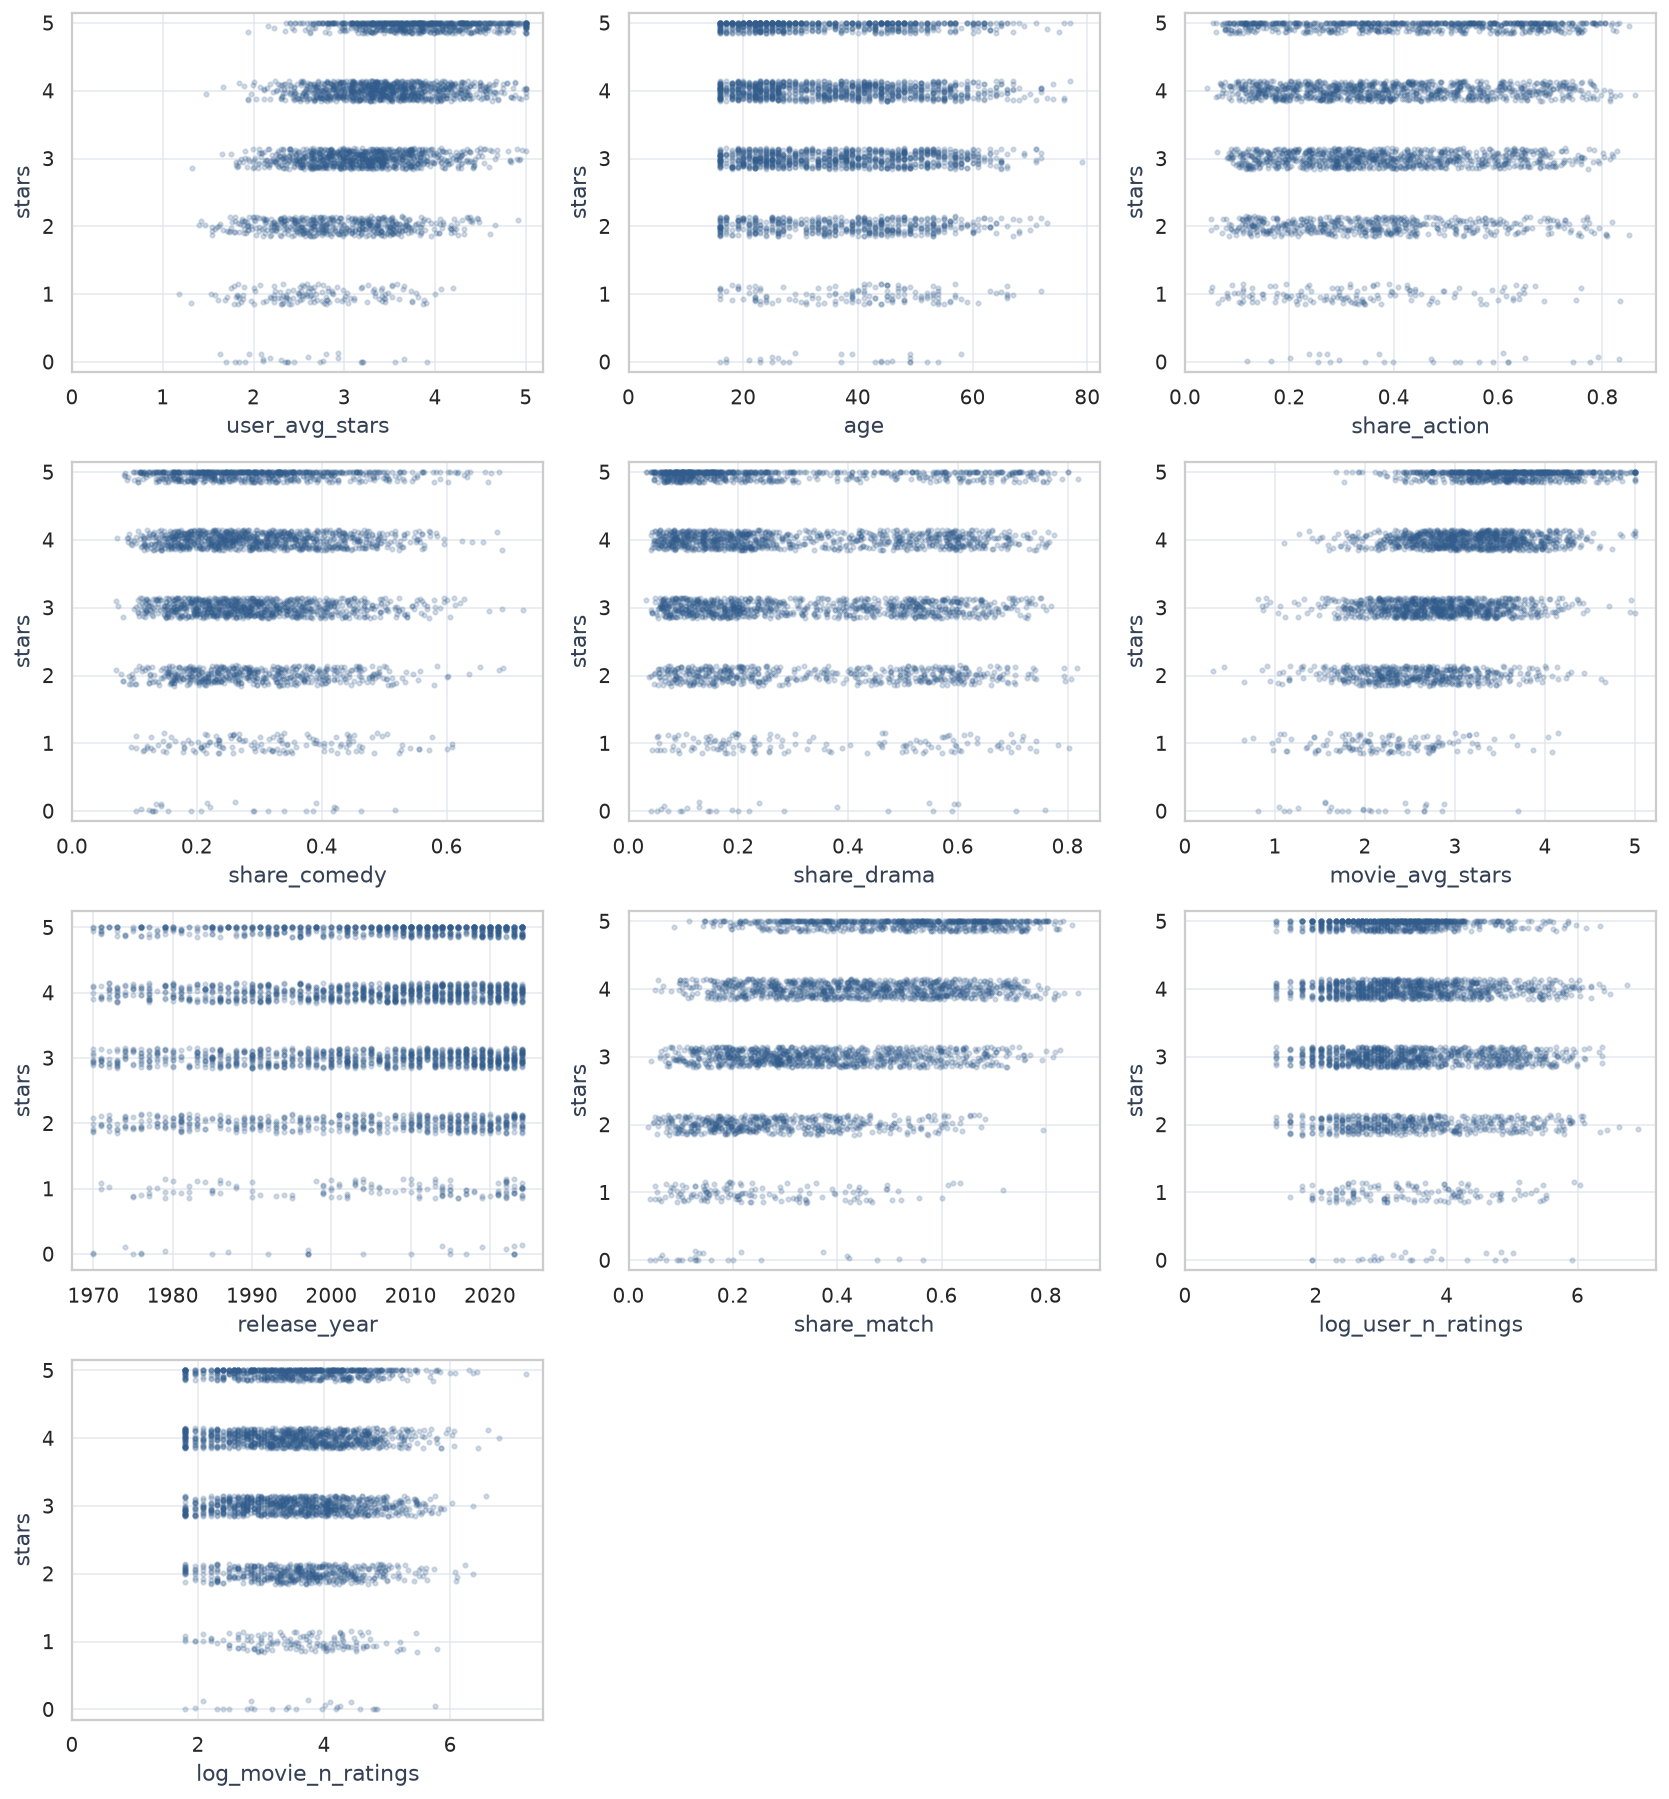

In [154]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    ax.scatter(df[f], y_jit, alpha=0.2, s=6)
    ax.set_xlabel(f); ax.set_ylabel("stars")
    if f != "release_year":
        fix_axes(ax)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

- Como esperado, usuários que tem uma maior média de estrelas costumam dar estrelas maiores; o mesmo acontece com filmes que tem avaliação média maior;
- Há uma impressão de que usuários com mais avaliações dão mais estrelas 3, mas isso pode ser apenas pela própria distribuição de estrelas; o mesmo acontece com filmes mais avaliados;
- Em primeiro momento, usuários mais velhos parecem não gostar de dar estrelas baixas. Apesar disso, é inconclusivo: temos poucas estrelas baixas e poucos usuários mais velhos. As outras faixas estão bem distribuídas;
- Há uma desconcentração de pontos para usuários com alta proporção de filmes de ação assistidos e estrelas baixas, especialmente a partir de 2 estrelas; para a proporção de filmes de comédia, parece ter-se uma uniformidade maior ao longo de uma mesma estrela; o mesmo acontece com os filmes de drama;
- O ano do filme parece não ter relação com o número de estrelas dado;
- O último gráfico mostra no eixo x a porcentagem do gênero assistido do usuário que é o gênero do filme. Ou seja, o quanto o usuário assistiu daquele gênero tem relação positiva com o número de estrelas.

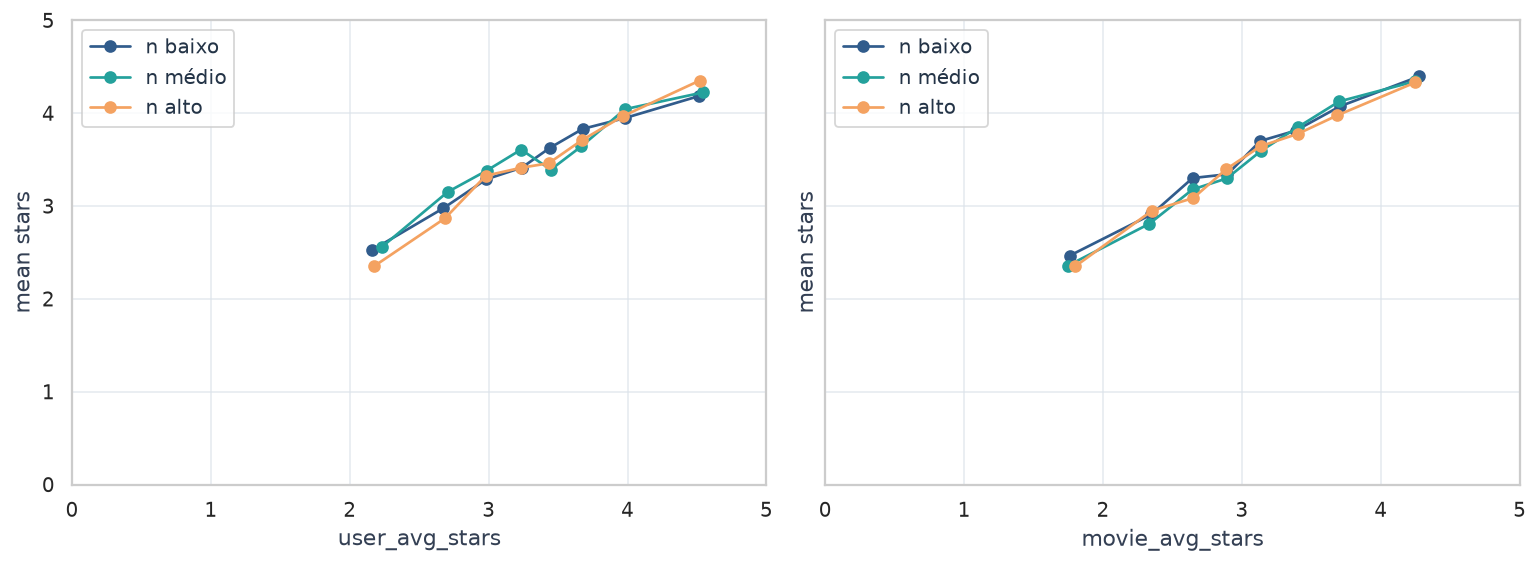

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (avg, n) in zip(axes, [("user_avg_stars", "log_user_n_ratings"),
                               ("movie_avg_stars", "log_movie_n_ratings")]):
    d = df.copy()
    d["n_grp"] = pd.qcut(d[n], 3, labels=["n baixo", "n médio", "n alto"])
    d["bin"] = pd.qcut(d[avg], 8, duplicates="drop")
    for g, sub in d.groupby("n_grp", observed=True):
        m = sub.groupby("bin", observed=True).agg(x=(avg, "mean"), y=("stars", "mean"))
        ax.plot(m["x"], m["y"], "o-", label=g)
    ax.set_xlabel(avg); ax.set_ylabel("mean stars"); ax.legend()
    ax.set_ylim(bottom=0, top=5)
    ax.set_xlim(left=0, right=5)
plt.tight_layout(); plt.show()

Os gráficos acima mostram linhas com baixo, médio, e alto número de avaliações (pelo usuário e para o filme), em relação ao número médio de estrelas. Como podemos ver, a confiabilidade da avaliação parece não ter relação com o número de avaliações, o que é surpreendente e descarta a possibilidade de interação.

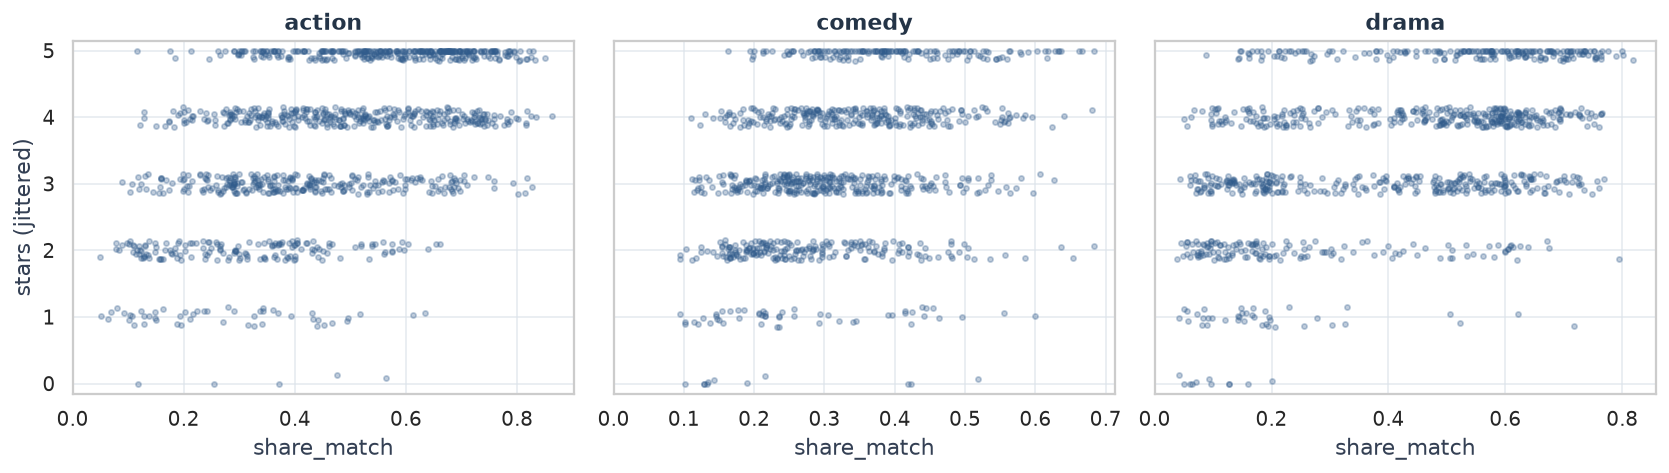

In [156]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, g in zip(axes, ["action", "comedy", "drama"]):
    d = df[df["genre"] == g]
    yj = (d["stars"] + rng.uniform(-0.15, 0.15, len(d))).clip(0, 5)
    ax.scatter(d["share_match"], yj, alpha=0.3, s=8)
    ax.set_title(g); ax.set_xlabel("share_match")
    fix_axes(ax)
axes[0].set_ylabel("stars (jittered)")
plt.tight_layout(); plt.show()

Como visto anteriormente, especialmente para o gênero ação, usuários dão mais estrelas para gêneros que assistem mais.

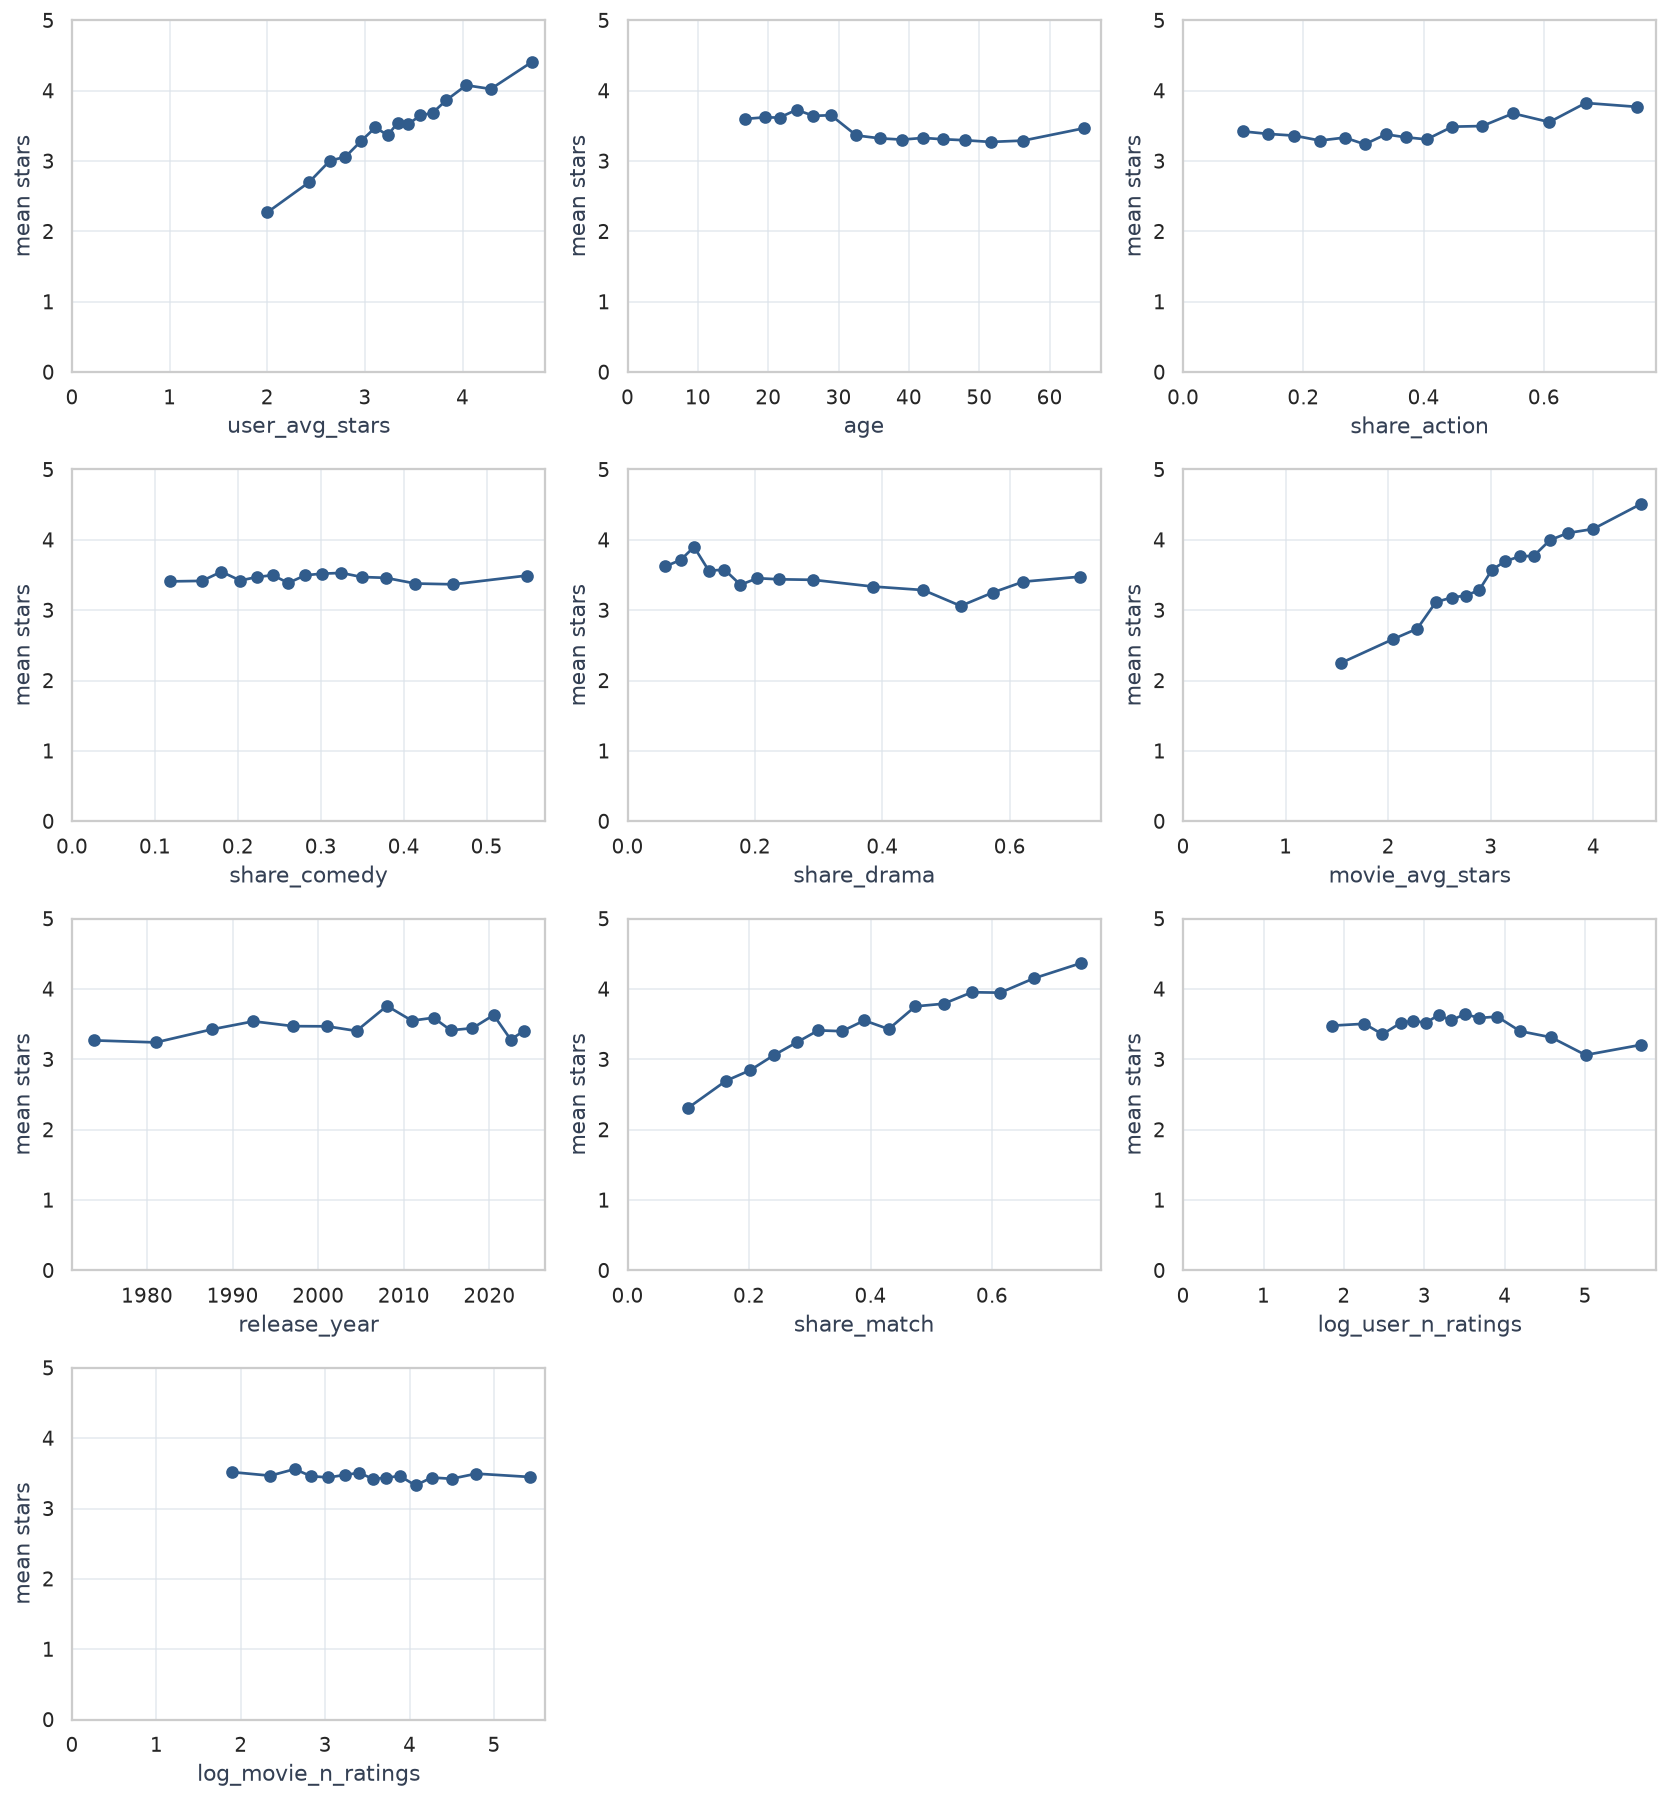

In [157]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    b = pd.qcut(df[f], 15, duplicates="drop")
    m = df.groupby(b, observed=True).agg(x=(f, "mean"), y=("stars", "mean"))
    ax.plot(m["x"], m["y"], "o-")
    ax.set_xlabel(f); ax.set_ylabel("mean stars")
    if f != "release_year":
        fix_axes(ax)
    ax.set_ylim(0, 5)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

O painel acima condensa parte das informações que obtivemos acima, sem a bagunça da nuvem de pontos. Dividimos as variáveis em 15 pontos e calculamos a média. Note que as 3 variáveis mais importantes analisadas são: as médias de avaliação e a proporção de filmes assistidos do mesmo gênero. Existem pequenas flutuações em release_year e age que podem indicar uma pequena relação até conjunta. As variáveis de contagem mostrando padrões assimétricos concentrados que indicam que a transformação log realmente ajustaria melhor. 

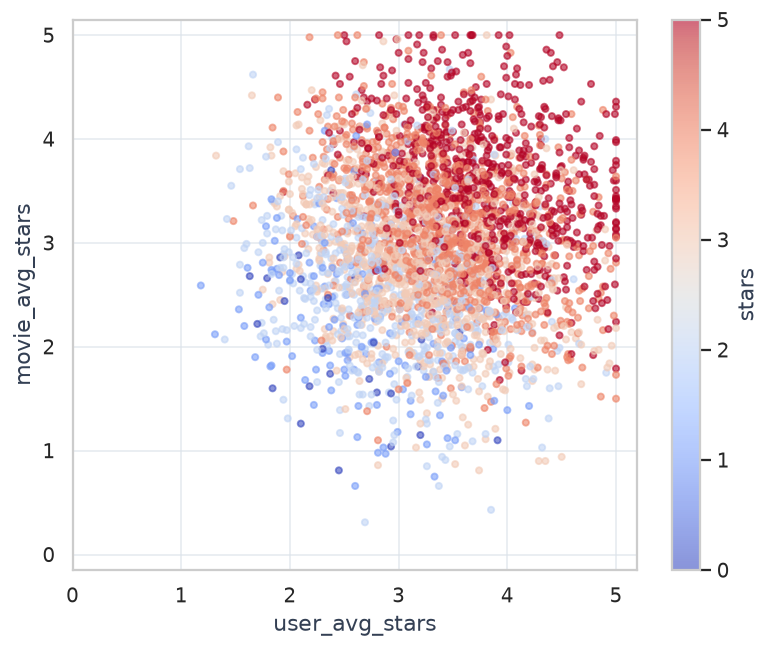

In [158]:
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(df["user_avg_stars"], df["movie_avg_stars"],
                 c=df["stars"], cmap="coolwarm", alpha=0.6, s=12)
plt.colorbar(sc, label="stars")
plt.xlabel("user_avg_stars"); plt.ylabel("movie_avg_stars")
fix_axes(plt.gca())
plt.show()

Parece que o efeito das variáveis de média é aditivo. Ainda assim, há uma mistura de cores no meio e nos cantos. Uma das hipóteses é que a outra variável importante, `share_match`, explica boa parte dessa confusão.

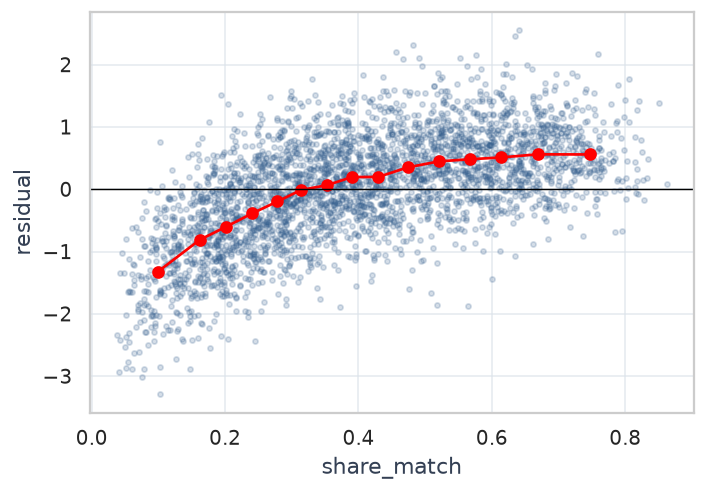

In [159]:
X_res = df[["user_avg_stars", "movie_avg_stars"]]
resid = df["stars"] - LinearRegression().fit(X_res, df["stars"]).predict(X_res)

plt.figure(figsize=(6, 4))
plt.scatter(df["share_match"], resid, alpha=0.2, s=8)
b = pd.qcut(df["share_match"], 15, duplicates="drop")
m = pd.DataFrame({"x": df["share_match"], "r": resid}).groupby(b, observed=True).mean()
plt.plot(m["x"], m["r"], "r-o")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("share_match"); plt.ylabel("residual")
plt.show()

Acima temos os resíduos de um modelo linear usando as médias, plotado contra a variável. Note que há um efeito forte. Na verdade, há várias interpretações importantes que surgem desse gráfico:

- Usuários que assistem pouco do gênero avaliam baixo; a partir de um certo momento, a adição de mais porcentagem de gênero não aumenta tanto a nota dada;
- A linha plotada dos resíduos cruza o eixo x em `share_match` próxima de 0.33 $\left(\frac{1}{3}\right)$, que é o caso em que não há preferência de gênero;
- Ainda há uma grande dispersão nos resíduos.

O que podemos levar além disso é que uma transformação na variável `share_match` parece de bom tom para manter um padrão claro nos pontos. Assim ppdemos aplicar o logaritmo natural, tratando esse comportamento.

#### Precisamos de mais variáveis?

In [160]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)

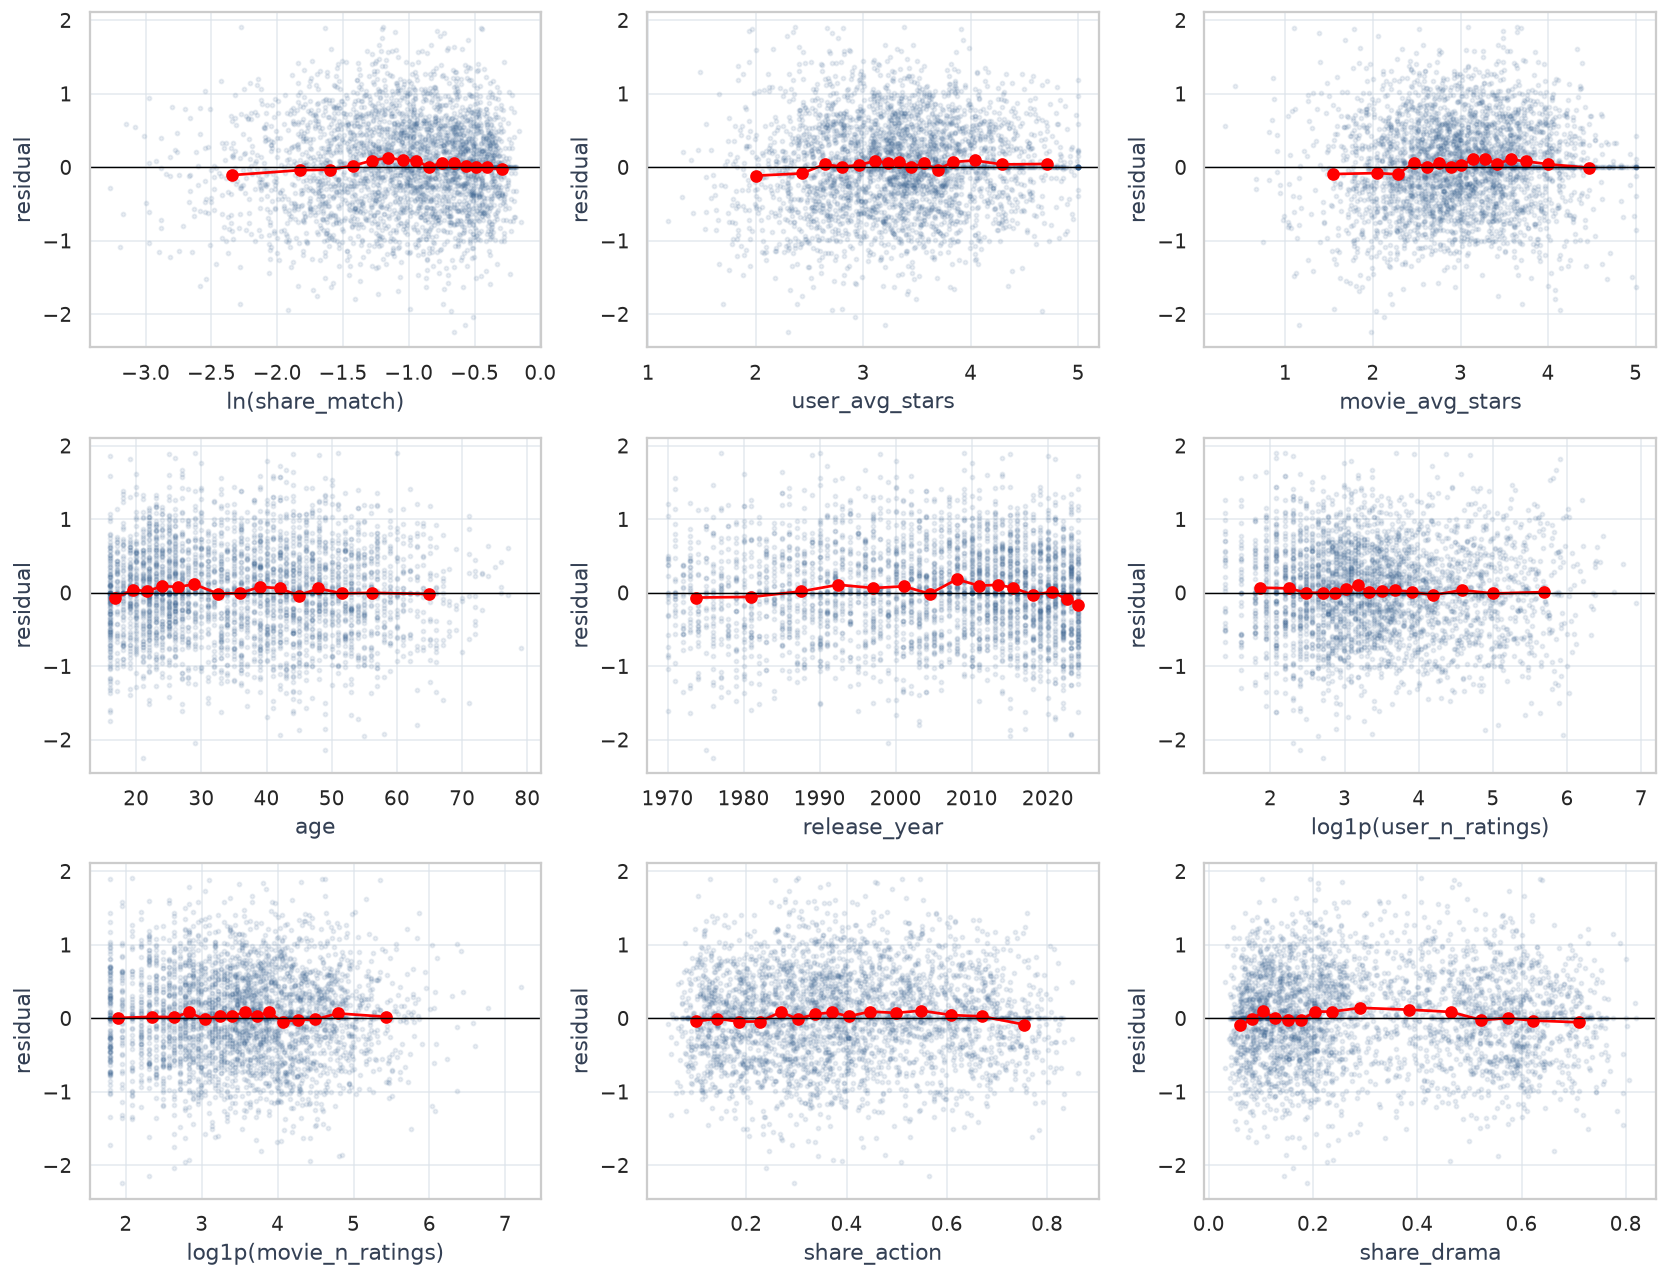

In [161]:
cands = {
    "ln(share_match)": X3["share_match"],
    "user_avg_stars": X2["user_avg_stars"],
    "movie_avg_stars": X2["movie_avg_stars"],
    "age": X2["age"],
    "release_year": X2["release_year"],
    "log1p(user_n_ratings)": np.log1p(X2["user_n_ratings"]),
    "log1p(movie_n_ratings)": np.log1p(X2["movie_n_ratings"]),
    "share_action": X2["share_action"],
    "share_drama": df["share_drama"],
}

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, (name, xf) in zip(axes.ravel(), cands.items()):
    b = pd.qcut(xf, 15, duplicates="drop")
    m = pd.DataFrame({"x": xf, "r": resid}).groupby(b, observed=True).mean()
    ax.scatter(xf, resid, alpha=0.1, s=5)
    ax.plot(m["x"], m["r"], "r-o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(name); ax.set_ylabel("residual")
plt.tight_layout(); plt.show()

Vemos que todas as variáveis e algumas de suas modificações não puxam o resíduo para algum lado. Para melhorar, devemos considerar outros modelos ou criar novas variáveis a partir das que temos.

### Análise das variáveis expressadas no modelo

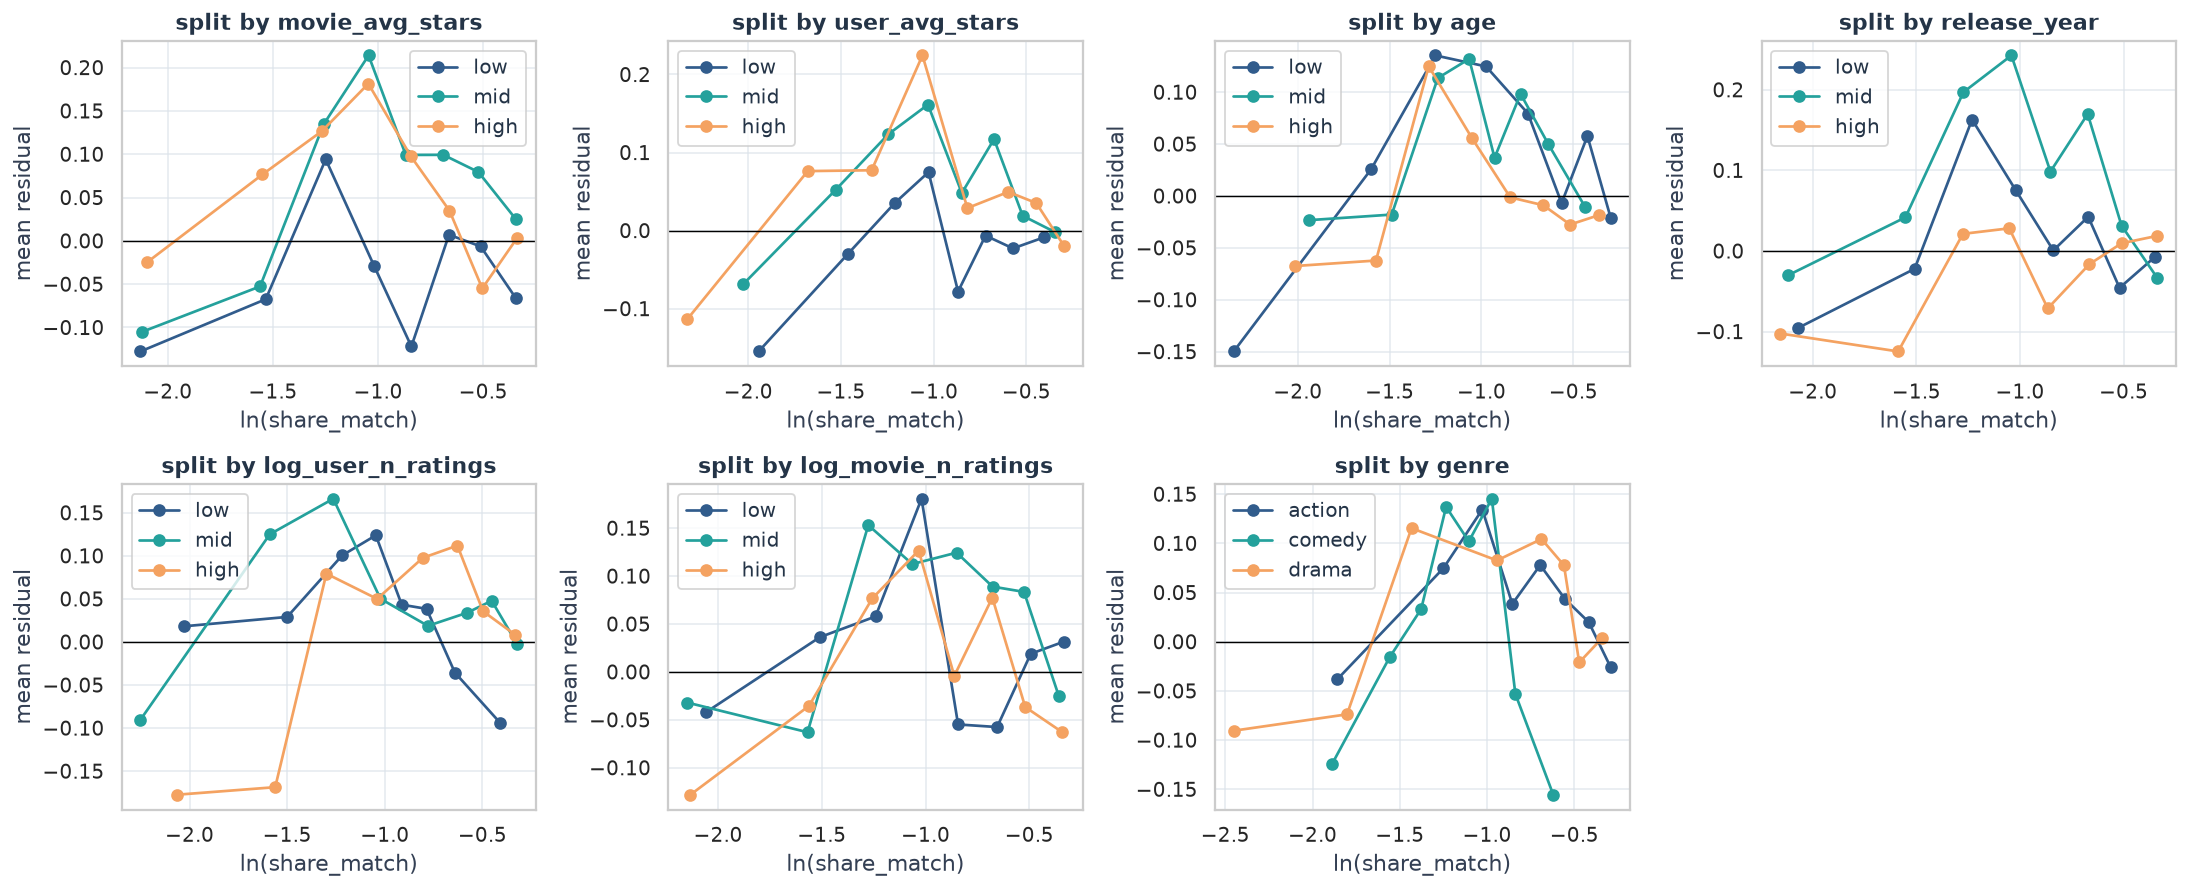

In [184]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)
resid = np.asarray(resid)

cands = {
    "movie_avg_stars": X3["movie_avg_stars"],
    "user_avg_stars": X3["user_avg_stars"],
    "age": X3["age"],
    "release_year": X3["release_year"],
    "log_user_n_ratings": np.log(X3["user_n_ratings"] + 1),
    "log_movie_n_ratings": np.log(X3["movie_n_ratings"] + 1),
    "genre": df["genre"],
}

xs = X3["share_match"].to_numpy()               # ln(share_match)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, g) in zip(axes.ravel(), cands.items()):
    if name == "genre":
        labels = sorted(g.unique())
    else:
        g = pd.qcut(g, 3, labels=["low", "mid", "high"])
        labels = ["low", "mid", "high"]
    for lab in labels:
        idx = (g == lab).to_numpy()
        xi, ri = xs[idx], resid[idx]
        b = pd.qcut(xi, 8, duplicates="drop")    # positional, no index involved
        m = pd.DataFrame({"x": xi, "r": ri}).groupby(b, observed=True).mean()
        ax.plot(m["x"], m["r"], "o-", label=lab)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"split by {name}")
    ax.set_xlabel("ln(share_match)"); ax.set_ylabel("mean residual")
    ax.legend()
for ax in axes.ravel()[len(cands):]:
    ax.axis("off")
plt.tight_layout(); plt.show()


Os perfis não expressam relação clara entre as variáveis, assim nos resta trabalhar somente com o que temos capturando e testando possibilidades através de seleções intuitivas.

Uma ideia é levar em conta a idade e o ano de lançamento por meio de uma interação, para tentar capturar a idade do usuário na época e tratar uma interação dessas variáveis. Criamos assim :

- `age_at_release`: equivalente à idade que o usuário possuía quando assistiu ao filme;
- `age_x_year`: Interação de idade e lançamento do filme

e englobamos em nossa análise para dar continuidade:

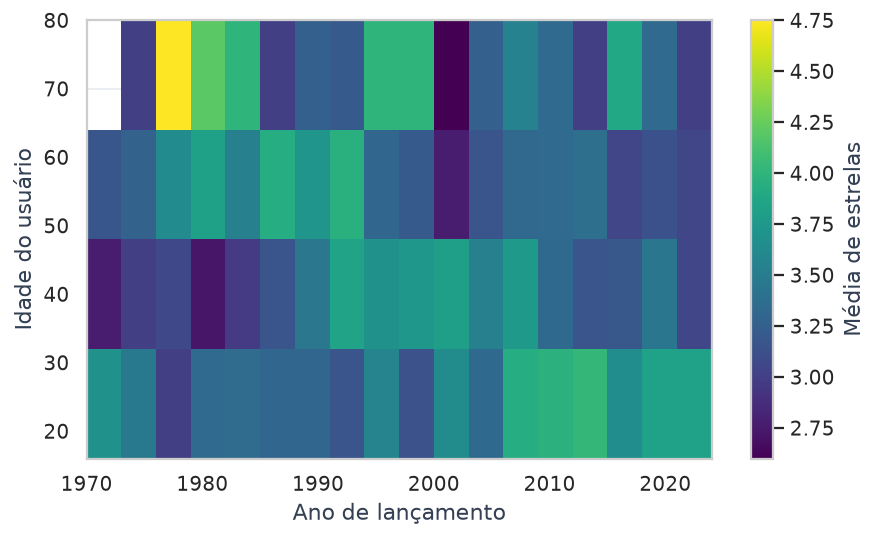

In [163]:
bins_x = np.arange(df["release_year"].min(), df["release_year"].max() + 3, 3)
bins_y = np.arange(df["age"].min(), df["age"].max() + 16, 16)
estatistica, bx, by, _ = binned_statistic_2d(
    df["release_year"], df["age"], df["stars"],
    statistic="mean", bins=[bins_x, bins_y]
)
fig, ax = plt.subplots(figsize=(7, 4.3))
malha = ax.pcolormesh(bx, by, estatistica.T, cmap="viridis")
fig.colorbar(malha, ax=ax, label="Média de estrelas")
ax.set_xlabel("Ano de lançamento")
ax.set_ylabel("Idade do usuário")
plt.tight_layout()
plt.show()

Essa relação é realmente interessante, pois mostra que usuários mais jovens tendem a dar notas mais altas para filmes lançados recentemente, enquanto usuários mais velhos tendem a ser mais críticos com filmes recentes. Além disso, há uma faixa de idade (aproximadamente entre 30 e 50 anos) que parece ser mais neutra em relação ao ano de lançamento, dando notas mais consistentes independentemente do ano do filme.

##### Analisando as variáveis novas 

In [164]:
df_feat = add_features(df)
df_feat[["log_user_n_ratings", "log_movie_n_ratings", "share_match",
         "age_x_year", "age_at_release"]].describe().T

,count,mean,std,min,25%,50%,75%,max
log_user_n_ratings,3200.0,3.463149,1.043895,1.386294,2.708050,3.332205,4.110874,6.924612
log_movie_n_ratings,3200.0,3.557656,0.940861,1.791759,2.833213,3.555348,4.208396,7.204893
share_match,3200.0,0.403375,0.187669,0.038000,0.249000,0.389000,0.555000,0.862000
age_x_year,3200.0,73034.833750,28046.873032,31520.000000,48282.000000,70934.000000,94211.500000,159817.000000
age_at_release,3200.0,14.625937,20.388699,-40.000000,1.000000,15.000000,29.000000,76.000000


#### Nova Relação Multicolinear 

In [165]:
vif_df3 = vif_table(df_feat[[
    "user_avg_stars", "log_user_n_ratings", "movie_avg_stars", "log_movie_n_ratings",
    "age_x_year", "age_at_release", "share_match", "age",
]])
vif_df3

,Variável,VIF
4,age_x_year,17980.392584
7,age,17337.591789
5,age_at_release,14.275420
1,log_user_n_ratings,1.047963
0,user_avg_stars,1.036055
6,share_match,1.005933
3,log_movie_n_ratings,1.003209
2,movie_avg_stars,1.000834


**Comentários**

Vemos que o VIF é bem melhor controlado nesse caso, constituindo um conjunto ótimo de valores para análise.

## Modelagem
### Regressão Linear

#### Modelos de referência

Antes dos modelos lineares, registramos dois pontos de comparação: a constante (média de `stars`) e a regressão linear com todas as variáveis **originais.**

In [166]:
results["Constante"] = evaluate(DummyRegressor(strategy="mean"), X, y)
results["Linear"] = evaluate(make_pipeline(StandardScaler(), LinearRegression()), X, y)
results_table()

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"


#### Linear com as novas variáveis

In [167]:
formula_new = """stars ~ user_avg_stars + log_user_n_ratings + age + age_x_year + age_at_release
             + movie_avg_stars + log_movie_n_ratings
             + genre_comedy + genre_drama + share_match"""

with warnings.catch_warnings():
    # age_at_release = age + release_year - 2026: a matriz é deficiente de posto (esperado).
    warnings.simplefilter("ignore")
    ols_new = smf.ols(formula_new, data=df_feat).fit()
print(ols_new.summary())

                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.691
Model:                            OLS   Adj. R-squared:                  0.690
Method:                 Least Squares   F-statistic:                     714.4
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:58:52   Log-Likelihood:                -3156.1
No. Observations:                3200   AIC:                             6334.
Df Residuals:                    3189   BIC:                             6401.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -1.4099    

In [168]:
X7 = build_X7(df)

results["Linear (Variáveis Transformadas)"] = evaluate(
    make_pipeline(StandardScaler(), LinearRegression()), X7, y)
results_table(["Linear (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
Linear (Variáveis Transformadas),0.6347,0.0035,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Após a inclusão variáveis novas, o RMSE melhorou e muito em relação ao modelo linear simples das variáveis originais. A saturação do modelo trouxe ganhos de performance e a partir de agora é possível considerar os demais modelos somente através das variáveis indicadas e transformadas

### Novos Modelos 

#### Regressão Logística Ordinal

Conforme a característica intrínseca ordinal dos dados, é possível analisar ajustar um modelo que determine bem essa relação

In [169]:
# Ajuste com statsmodels para interpretar os coeficientes (pure_train completo).
X7 = build_X7(df)
valores_estrelas = sorted(y.unique())
y_ordinal = pd.Categorical(y, categories=valores_estrelas, ordered=True)

resultado_ordinal = OrderedModel(y_ordinal, X7, distr="logit").fit(method="bfgs", disp=False)
print(resultado_ordinal.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -2893.5
Model:                   OrderedModel   AIC:                             5817.
Method:            Maximum Likelihood   BIC:                             5908.
Date:                Sun, 22 Nov 2026                                         
Time:                        19:58:54                                         
No. Observations:                3200                                         
Df Residuals:                    3185                                         
Df Model:                          10                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
user_avg_stars          2.3650        nan        nan        nan         nan         nan
log_user_n_ratings     -0

/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1189: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = fit_method(
/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1189: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = fit_method(


In [170]:
results["Regressão ordinal (Variáveis Transformadas)"] = evaluate(
    make_pipeline(StandardScaler(), OrdinalRegressor(distr="logit")), X7, y)
results_table(["Regressão ordinal (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
Regressão ordinal (Variáveis Transformadas),0.6243,0.0039,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado é ligeiramente melhor e parece trazer melhor informação acerca dos dados. Vamos avançar trazendo modeloagens mais abruptas.

### Random Forest

\{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.8, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': -1, 'oob_score': False, 'random_state': 2026, 'verbose': 0, 'warm_start': False\}

In [171]:
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=5,
    max_features=0.80,
    n_jobs=-1,
    random_state=SEED)

results["Random Forest (Variáveis Transformadas)"] = evaluate(rf, X7, y)
results_table(["Random Forest (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
Random Forest (Variáveis Transformadas),0.5708,0.003,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado é interessante e parece melhor e tanto o nosso repertório apesar da perda grande de interpretabilidade. Sobretudo, existem possibilidades de ganho marginal sobre tais métodos usando algoritmos conjuntos que viabilizam melhores parâmetros e desempenho

### XGBoost

In [172]:
xgb_best = XGBRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=3,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, tree_method="hist",
    random_state=SEED, n_jobs=-1)

results["XGBoost (Variáveis Transformadas)"] = evaluate(xgb_best, X7, y)
results_table(["XGBoost (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
XGBoost (Variáveis Transformadas),0.5105,0.0034,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


### LightGBM

In [173]:
lightgbm_best = LGBMRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=3,
    min_child_samples=5, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEED, n_jobs=-1)
results["LightGBM (Variáveis Transformadas)"] = evaluate(lightgbm_best, X7, y)
results_table(["LightGBM (Variáveis Transformadas)"])   

,CV RMSE,SE,Variables
LightGBM (Variáveis Transformadas),0.5146,0.0032,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Tais modelos competem entre os melhores ajustados, sobretudo a sua capacidade de overfitting nos dados é muito alto, mostrando assim a possibilidade perigosa de decorar o ruído dos dados e limitar nossa capacidade preditiva. 

### K-NN

O K-NN depende de distâncias, então padronizamos as variáveis dentro do pipeline (o scaler é ajustado só no treino de cada fold).

In [174]:
results["KNN - k = 10 (Variáveis Transformadas)"] = evaluate(
    make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10, weights="distance")), X7, y)
results_table(["KNN - k = 10 (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
KNN - k = 10 (Variáveis Transformadas),0.6558,0.0042,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


### K-Means + K-NN nos centroides

Em cada fold, o K-Means encontra seis grupos usando os dados de treino. Depois, um K-NN associa cada ponto de
validação ao centroide mais próximo. A nota prevista é a média de `stars` dos pontos de treino daquele grupo.
Padronizar evita que variáveis em escalas maiores dominem as distâncias.

In [175]:
kmeans_knn = make_pipeline(
    StandardScaler(),
    KMeansCentroidRegressor(n_clusters=6, random_state=SEED)
)

results["K-Means + K-NN nos centroides (Variáveis Transformadas)"] = evaluate(kmeans_knn, X7, y)
results_table(["K-Means + K-NN nos centroides (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
K-Means + K-NN nos centroides (Variáveis Transformadas),1.0936,0.0023,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


O resultado não é nada melhor que o modelo clássico, isto mostra que a suavização não evita erros mas traz falsas generalizações para a nossa separação

### MLP regularizado com otimizador Adam

Rede neural com duas camadas ocultas (128 e 64 neurônios), penalização L2 (`alpha`) e parada antecipada. 

A penalização reduz coeficientes grandes; o early stopping interrompe o ajuste quando a validação interna deixa de melhorar.
Comparamos duas configurações: tanh com `alpha` alto (melhor configuração encontrada) e ReLU com `alpha = 0.01` padrão sickit-learn

In [176]:
best_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        solver="adam",
        hidden_layer_sizes=(128, 64),
        activation="tanh",
        alpha=0.25956879983111314,
        batch_size=128,
        learning_rate="constant",
        learning_rate_init=0.0002674064237843672,
        momentum=0.8,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=40,
        tol=1e-4,
        random_state=SEED
    )
)

results["Best MLP [128, 64] alpha=0.26 (Variáveis Transformadas)"] = evaluate(best_mlp, X7, y)

In [177]:
mlp_relu = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.01,                 # penalização L2
        learning_rate_init=0.001,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=SEED
    )
)

results["MLP ReLU (128, 64) alpha=0.01 (Variáveis Transformadas)"] = evaluate(mlp_relu, X7, y)

#### Comparação das ativações do MLP

In [178]:
results_table(["Best MLP [128, 64] alpha=0.26 (Variáveis Transformadas)", "MLP ReLU (128, 64) alpha=0.01 (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
"Best MLP [128, 64] alpha=0.26 (Variáveis Transformadas)",0.4984,0.0035,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"
"MLP ReLU (128, 64) alpha=0.01 (Variáveis Transformadas)",0.5377,0.0042,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Esse resultado foi fruto de testes contínuos de parâmetros e discussão entre os participantes do grupo e refletiu o melhor comportamento.

### SVM (Support Vector Regression)

O SVR com kernel RBF depende de escalas comparáveis entre as variáveis; a padronização é ajustada dentro de cada fold para evitar vazamento.

In [179]:
results["SVR (Variáveis Transformadas)"] = evaluate(
    make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1, epsilon=0.1, gamma="scale")), X7, y)
results_table(["SVR (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
SVR (Variáveis Transformadas),0.5537,0.0047,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


Dentre todas, esse modelo se alinhou as expectativas e ofereceu boas análises. Sobretudo devido a não abordagem em aula e também preferência no quesito de generalização, não continuamos o processo. 

### Regressão LASSO

In [180]:
# Padroniza as variáveis e aplica penalização L1 para selecionar/regularizar coeficientes.
lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01, max_iter=10000)
)

results["Regressão LASSO (Variáveis Transformadas)"] = evaluate(lasso, X7, y)
results_table(["Regressão LASSO (Variáveis Transformadas)"])

,CV RMSE,SE,Variables
Regressão LASSO (Variáveis Transformadas),0.6585,0.0025,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama"


**Os resultados de cada modelo são calculados em sua própria seção. A comparação conjunta aparece abaixo.**

### Comparação Final dos Modelos

Cada modelo registrado em `results` é reajustado em todo o `pure_train`, com a mesma matriz de variáveis usada
na validação cruzada, e avaliado no `hold_out` (20% separados no início). A tabela traz o RMSE da validação
cruzada, o erro-padrão, as variáveis usadas, o RMSE no hold-out e a diferença entre os dois.

In [181]:
# Hold-out evaluation for every model in `results`
y_holdout = hold_out["stars"]

# Each model is matched to the builder of its feature matrix, which is then applied to the hold-out.
train_sets = {name: build(pure_train) for name, build in FEATURE_SETS.items()}
holdout_sets = {name: build(hold_out) for name, build in FEATURE_SETS.items()}

def matching_feature_set(X_train_model):
    for name, X_k in train_sets.items():
        if X_train_model.equals(X_k):
            return name
    raise ValueError("Could not identify the feature set used by the model.")

holdout_rmse = []
for model, X_train_model in evaluation_specs:
    name = matching_feature_set(X_train_model)
    X_test_model = holdout_sets[name][X_train_model.columns]

    fitted_model = clone(model).fit(X_train_model, y)
    predictions = np.clip(fitted_model.predict(X_test_model), 0, 5)
    holdout_rmse.append(np.sqrt(mean_squared_error(y_holdout, predictions)))

if len(holdout_rmse) != len(results):
    raise ValueError(
        f"Mismatch: {len(results)} result rows but {len(holdout_rmse)} hold-out scores."
    )

results_df = pd.DataFrame(
    results, index=["CV RMSE", "SE", "Variables"]
).T

results_df["CV RMSE"] = pd.to_numeric(results_df["CV RMSE"])
results_df["SE"] = pd.to_numeric(results_df["SE"])
results_df["Hold-out RMSE"] = np.round(holdout_rmse, 4)
results_df["Difference (Hold-out - CV)"] = (
    results_df["Hold-out RMSE"] - results_df["CV RMSE"]
).round(4)

results_df.sort_values("CV RMSE")

,CV RMSE,SE,Variables,Hold-out RMSE,Difference (Hold-out - CV)
"Best MLP [128, 64] alpha=0.26 (Variáveis Transformadas)",0.4984,0.0035,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5063,0.0079
XGBoost (Variáveis Transformadas),0.5105,0.0034,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5123,0.0018
LightGBM (Variáveis Transformadas),0.5146,0.0032,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5165,0.0019
"MLP ReLU (128, 64) alpha=0.01 (Variáveis Transformadas)",0.5377,0.0042,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5311,-0.0066
SVR (Variáveis Transformadas),0.5537,0.0047,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5529,-0.0008
Random Forest (Variáveis Transformadas),0.5708,0.0030,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.5611,-0.0097
Regressão ordinal (Variáveis Transformadas),0.6243,0.0039,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.6189,-0.0054
Linear (Variáveis Transformadas),0.6347,0.0035,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.6211,-0.0136
KNN - k = 10 (Variáveis Transformadas),0.6558,0.0042,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.6507,-0.0051
Regressão LASSO (Variáveis Transformadas),0.6585,0.0025,"user_avg_stars, log_user_n_ratings, age, share_match, age_x_year, age_at_release, movie_avg_stars, log_movie_n_ratings, genre_comedy, genre_drama",0.6434,-0.0151


### README e Requirements

In [182]:
# Requirements

from importlib.metadata import version

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels",
            "scikit-learn", "lightgbm", "xgboost"]

with open("requirements.txt", "w") as f:
    for p in packages:
        f.write(f"{p}=={version(p)}\n")

print(open("requirements.txt").read())

numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
scipy==1.18.1
statsmodels==0.15.0
scikit-learn==1.9.1
lightgbm==4.7.0
xgboost==3.4.1



In [183]:
def write_readme(results_df, path="README.md",
                 title="Projeto MAE0501: Prevendo avaliações de filmes"):

    rows = results_df.sort_values("CV RMSE").iterrows()

    table = [
        "| Model | CV RMSE | SE | Variables | Hold-out RMSE | Difference |",
        "|---|---:|---:|---|---:|---:|"
    ]

    for name, row in rows:
        table.append(
            f"| {name} "
            f"| {row['CV RMSE']:.4f} "
            f"| {row['SE']:.4f} "
            f"| {row['Variables']} "
            f"| {row['Hold-out RMSE']:.4f} "
            f"| {row['Difference (Hold-out - CV)']:.4f} |"
        )

    text = f"""# {title}

## Requirements

```bash
python -m pip install -r requirements.txt
```

## Resultados

RMSE por Validação Cruzada 5-fold 3 vezes em `pure_train`;

{chr(10).join(table)}
"""
    Path(path).write_text(text, encoding="utf-8")
    print(f"{path} written ({len(results_df)} models)")

write_readme(results_df)

README.md written (13 models)
